In [1]:
# === Ячейка 1. Импорты и константы ===
import os
import gc
import json
import shutil

import numpy as np
import pandas as pd
import torch

from datasets import Dataset, DatasetDict
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    TrainingArguments,
    Trainer,
    EarlyStoppingCallback,
    pipeline,
)
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

SEED = 42
DEVICE = 0 if torch.cuda.is_available() else -1

np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print('DEVICE:', DEVICE, '| CUDA:', torch.cuda.is_available())

DEVICE: 0 | CUDA: True


In [2]:
# === Ячейка 2. Загрузка датасета rureviews ===
DATASET_URL = 'https://raw.githubusercontent.com/sismetanin/rureviews/master/women-clothing-accessories.3-class.balanced.csv'

# В файле колонки: review, sentiment. Разделитель — табуляция.
df = pd.read_csv(DATASET_URL, sep='\t')
print('Размер:', df.shape)
df.head()

Размер: (90000, 2)


,review,sentiment
0,качество плохое пошив ужасный (горловина напер...,negative
1,"Товар отдали другому человеку, я не получила п...",negative
2,"Ужасная синтетика! Тонкая, ничего общего с пре...",negative
3,"товар не пришел, продавец продлил защиту без м...",negative
4,"Кофточка голая синтетика, носить не возможно.",negative


In [3]:
# === Ячейка 3. Приведение к единому виду: text/label, числовые метки ===
df = df.rename(columns={'review': 'text', 'sentiment': 'label'})

label_map_if_str = {
    'neutral': 0, 'нейтрально': 0, 'neautral': 0,
    'positive': 1, 'позитив': 1, 'положительно': 1,
    'negative': 2, 'негатив': 2, 'отрицательно': 2,
}

def cast_label(y):
    if isinstance(y, str):
        return label_map_if_str[y.strip().lower()]
    return int(y)

df['text'] = df['text'].astype(str)
df['label'] = df['label'].apply(cast_label)

print(df['label'].value_counts().sort_index())
df.head()

label
0    30000
1    30000
2    30000
Name: count, dtype: int64


,text,label
0,качество плохое пошив ужасный (горловина напер...,2
1,"Товар отдали другому человеку, я не получила п...",2
2,"Ужасная синтетика! Тонкая, ничего общего с пре...",2
3,"товар не пришел, продавец продлил защиту без м...",2
4,"Кофточка голая синтетика, носить не возможно.",2


In [4]:
# === Ячейка 4. Стратифицированное деление на train / validation ===
df = df.sample(frac=1, random_state=SEED).reset_index(drop=True)

val_parts, train_parts = [], []
for cls, grp in df.groupby('label'):
    n_val = int(len(grp) * 0.2)
    val_parts.append(grp.iloc[:n_val])
    train_parts.append(grp.iloc[n_val:])

train_df = pd.concat(train_parts).sample(frac=1, random_state=SEED).reset_index(drop=True)
valid_df = pd.concat(val_parts).sample(frac=1, random_state=SEED).reset_index(drop=True)

raw = DatasetDict({
    'train': Dataset.from_pandas(train_df[['text', 'label']], preserve_index=False),
    'validation': Dataset.from_pandas(valid_df[['text', 'label']], preserve_index=False),
})
raw

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 72000
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 18000
    })
})

In [5]:
# === Ячейка 5. Ограничение размера выборки ===
# Ограничения не обязательны. Главное — корректная и репрезентативная выборка.
MAX_TRAIN = 6000
MAX_VALID = 1500

train_ds = raw['train'].shuffle(seed=SEED)
valid_ds = raw['validation'].shuffle(seed=SEED)

if MAX_TRAIN is not None:
    train_ds = train_ds.select(range(min(MAX_TRAIN, len(train_ds))))
if MAX_VALID is not None:
    valid_ds = valid_ds.select(range(min(MAX_VALID, len(valid_ds))))

dataset = DatasetDict({'train': train_ds, 'validation': valid_ds})
print(dataset)
print(pd.Series(dataset['train']['label']).value_counts().sort_index())
print(pd.Series(dataset['validation']['label']).value_counts().sort_index())

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 6000
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 1500
    })
})
0    1989
1    2074
2    1937
Name: count, dtype: int64
0    511
1    508
2    481
Name: count, dtype: int64


In [6]:
# === Ячейка 6. Маппинги меток и примеры для проверки моделей ===
ID2LABEL = {0: 'NEUTRAL', 1: 'POSITIVE', 2: 'NEGATIVE'}
LABEL2ID = {v: k for k, v in ID2LABEL.items()}

examples = [
    'Платье отличное, ткань приятная, села по фигуре, очень довольна покупкой!',
    'Сумка пришла с оторванной ручкой, ужасное качество, деньги на ветер.',
    'Заказ доставили вовремя, размер совпал с таблицей, в целом нормально.',
    'Туфли красивые, но натирают пятку после получаса носки.',
    'Шарф мягкий и тёплый, цвет как на фото, рекомендую продавца.',
]

In [7]:
# === Ячейка 7. Готовые модели через pipeline ===
PIPELINE_MODELS = [
    'blanchefort/rubert-base-cased-sentiment',
    'cointegrated/rubert-tiny-sentiment-balanced',
]

for model_name in PIPELINE_MODELS:
    print('MODEL:', model_name)
    clf = pipeline(
        'sentiment-analysis',
        model=model_name,
        tokenizer=model_name,
        device=DEVICE,
        truncation=True,
    )
    for text in examples:
        print(text, '->', clf(text))

MODEL: blanchefort/rubert-base-cased-sentiment


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: blanchefort/rubert-base-cased-sentiment
Key                          | Status     |  | 
-----------------------------+------------+--+-
bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Платье отличное, ткань приятная, села по фигуре, очень довольна покупкой! -> [{'label': 'POSITIVE', 'score': 0.9813938140869141}]
Сумка пришла с оторванной ручкой, ужасное качество, деньги на ветер. -> [{'label': 'NEGATIVE', 'score': 0.7514608502388}]
Заказ доставили вовремя, размер совпал с таблицей, в целом нормально. -> [{'label': 'POSITIVE', 'score': 0.5889137387275696}]
Туфли красивые, но натирают пятку после получаса носки. -> [{'label': 'NEUTRAL', 'score': 0.7257443070411682}]
Шарф мягкий и тёплый, цвет как на фото, рекомендую продавца. -> [{'label': 'POSITIVE', 'score': 0.9811044931411743}]
MODEL: cointegrated/rubert-tiny-sentiment-balanced


Loading weights:   0%|          | 0/57 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: cointegrated/rubert-tiny-sentiment-balanced
Key                          | Status     |  | 
-----------------------------+------------+--+-
bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Платье отличное, ткань приятная, села по фигуре, очень довольна покупкой! -> [{'label': 'positive', 'score': 0.9957406520843506}]
Сумка пришла с оторванной ручкой, ужасное качество, деньги на ветер. -> [{'label': 'negative', 'score': 0.9154360294342041}]
Заказ доставили вовремя, размер совпал с таблицей, в целом нормально. -> [{'label': 'neutral', 'score': 0.611789882183075}]
Туфли красивые, но натирают пятку после получаса носки. -> [{'label': 'neutral', 'score': 0.6995685696601868}]
Шарф мягкий и тёплый, цвет как на фото, рекомендую продавца. -> [{'label': 'positive', 'score': 0.9943951368331909}]


In [8]:
# === Ячейка 8. Поэтапное предсказание без pipeline ===
def predict_step_by_step(model_name, texts):
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForSequenceClassification.from_pretrained(model_name)
    model.eval()
    if torch.cuda.is_available():
        model.cuda()

    batch = tokenizer(
        texts, padding=True, truncation=True, max_length=256, return_tensors='pt'
    )
    if torch.cuda.is_available():
        batch = {k: v.cuda() for k, v in batch.items()}

    with torch.no_grad():
        logits = model(**batch).logits
        probs = torch.softmax(logits, dim=-1).detach().cpu().numpy()

    id2label = model.config.id2label
    result = []
    for text, p in zip(texts, probs):
        pred_id = int(np.argmax(p))
        result.append({
            'text': text,
            'label': id2label.get(pred_id, str(pred_id)),
            'score': float(p[pred_id]),
            'all_probabilities': p.tolist(),
        })

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return result

for model_name in PIPELINE_MODELS:
    print('MODEL:', model_name)
    preds = predict_step_by_step(model_name, examples)
    for row in preds:
        print(row)

MODEL: blanchefort/rubert-base-cased-sentiment


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: blanchefort/rubert-base-cased-sentiment
Key                          | Status     |  | 
-----------------------------+------------+--+-
bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


{'text': 'Платье отличное, ткань приятная, села по фигуре, очень довольна покупкой!', 'label': 'POSITIVE', 'score': 0.9813938140869141, 'all_probabilities': [0.015021948143839836, 0.9813938140869141, 0.0035842405632138252]}
{'text': 'Сумка пришла с оторванной ручкой, ужасное качество, деньги на ветер.', 'label': 'NEGATIVE', 'score': 0.7514609098434448, 'all_probabilities': [0.18068811297416687, 0.0678509920835495, 0.7514609098434448]}
{'text': 'Заказ доставили вовремя, размер совпал с таблицей, в целом нормально.', 'label': 'POSITIVE', 'score': 0.58891361951828, 'all_probabilities': [0.3486253619194031, 0.58891361951828, 0.0624610111117363]}
{'text': 'Туфли красивые, но натирают пятку после получаса носки.', 'label': 'NEUTRAL', 'score': 0.7257444262504578, 'all_probabilities': [0.7257444262504578, 0.17317378520965576, 0.10108178108930588]}
{'text': 'Шарф мягкий и тёплый, цвет как на фото, рекомендую продавца.', 'label': 'POSITIVE', 'score': 0.9811044931411743, 'all_probabilities': [0.0

Loading weights:   0%|          | 0/57 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: cointegrated/rubert-tiny-sentiment-balanced
Key                          | Status     |  | 
-----------------------------+------------+--+-
bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


{'text': 'Платье отличное, ткань приятная, села по фигуре, очень довольна покупкой!', 'label': 'positive', 'score': 0.9957406520843506, 'all_probabilities': [0.0007916240720078349, 0.003467705799266696, 0.9957406520843506]}
{'text': 'Сумка пришла с оторванной ручкой, ужасное качество, деньги на ветер.', 'label': 'negative', 'score': 0.9154360294342041, 'all_probabilities': [0.9154360294342041, 0.08285818994045258, 0.0017057604854926467]}
{'text': 'Заказ доставили вовремя, размер совпал с таблицей, в целом нормально.', 'label': 'neutral', 'score': 0.611789882183075, 'all_probabilities': [0.18984641134738922, 0.611789882183075, 0.19836372137069702]}
{'text': 'Туфли красивые, но натирают пятку после получаса носки.', 'label': 'neutral', 'score': 0.699568510055542, 'all_probabilities': [0.23966170847415924, 0.699568510055542, 0.06076976656913757]}
{'text': 'Шарф мягкий и тёплый, цвет как на фото, рекомендую продавца.', 'label': 'positive', 'score': 0.9943951368331909, 'all_probabilities': 

In [9]:
# === Ячейка 9. Оценка готовых моделей на валидации ===
def normalize_pred_label(label):
    label = str(label).upper().strip()
    label_map = {
        'NEUTRAL': 0, 'LABEL_0': 0, '0': 0,
        'POSITIVE': 1, 'LABEL_1': 1, '1': 1,
        'NEGATIVE': 2, 'LABEL_2': 2, '2': 2,
    }
    if label not in label_map:
        raise ValueError(f'Неизвестная метка модели: {label}')
    return label_map[label]

PIPELINE_EVAL_SIZE = min(500, len(dataset['validation']))
eval_part = dataset['validation'].select(range(PIPELINE_EVAL_SIZE))

eval_texts = ['' if x is None else str(x) for x in eval_part['text']]
y_true = np.array([int(y) for y in eval_part['label']])

pipeline_results = []
for model_name in PIPELINE_MODELS:
    print(f'\nМодель: {model_name}')
    clf = pipeline(
        'sentiment-analysis',
        model=model_name,
        tokenizer=model_name,
        device=DEVICE,
        truncation=True,
    )
    preds = clf(eval_texts, batch_size=32, max_length=256, truncation=True)
    y_pred = np.array([normalize_pred_label(p['label']) for p in preds])

    acc = accuracy_score(y_true, y_pred)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average='macro', zero_division=0
    )
    pipeline_results.append({
        'model': model_name,
        'accuracy': acc,
        'macro_precision': precision,
        'macro_recall': recall,
        'macro_f1': f1,
    })

pipeline_results_df = pd.DataFrame(pipeline_results)
pipeline_results_df


Модель: blanchefort/rubert-base-cased-sentiment


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: blanchefort/rubert-base-cased-sentiment
Key                          | Status     |  | 
-----------------------------+------------+--+-
bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Модель: cointegrated/rubert-tiny-sentiment-balanced


Loading weights:   0%|          | 0/57 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: cointegrated/rubert-tiny-sentiment-balanced
Key                          | Status     |  | 
-----------------------------+------------+--+-
bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,model,accuracy,macro_precision,macro_recall,macro_f1
0,blanchefort/rubert-base-cased-sentiment,0.782,0.806526,0.787916,0.780921
1,cointegrated/rubert-tiny-sentiment-balanced,0.744,0.750438,0.747417,0.748467


In [10]:
# === Ячейка 10. Конфиги экспериментов для дообучения ===
FINETUNE_MODELS = [
    'cointegrated/rubert-tiny2',
    'DeepPavlov/distilrubert-small-cased-conversational',
]

# Принцип: baseline + по одному изменённому параметру в каждом следующем конфиге.
# Это позволяет сказать "вот этот параметр дал прирост/просадку", а не гадать.
#
# Ось, которую варьируем:
#   baseline             — точка отсчёта
#   high_lr              — влияние learning rate (2e-5 -> 5e-5)
#   cosine_scheduler     — влияние lr scheduler (linear -> cosine)
#   strong_regularization— влияние регуляризации (wd 0.01 -> 0.1)
#   large_batch          — влияние размера батча (16 -> 32)
#
# Всё остальное (эпохи, optimizer, ES, метрика, warmup) — одинаковое.
BASE_CFG = {
    'num_train_epochs': 8,
    'learning_rate': 2e-5,
    'lr_scheduler_type': 'linear',
    'optim': 'adamw_torch',
    'per_device_train_batch_size': 16,
    'per_device_eval_batch_size': 16,
    'gradient_accumulation_steps': 1,
    'weight_decay': 0.01,
    'warmup_ratio': 0.1,
    'metric_for_best_model': 'macro_f1',
    'fp16': True,
    'early_stopping': True,
    'early_stopping_patience': 2,
    'greater_is_better': True,
}

EXPERIMENT_CONFIGS = [
    # 1) Baseline — точка отсчёта
    {**BASE_CFG, 'name': 'baseline'},

    # 2) Влияние learning rate: 2e-5 -> 5e-5
    {**BASE_CFG, 'name': 'high_lr',
     'learning_rate': 5e-5},

    # 3) Влияние lr scheduler: linear -> cosine
    {**BASE_CFG, 'name': 'cosine_scheduler',
     'lr_scheduler_type': 'cosine'},

    # 4) Влияние регуляризации: wd 0.01 -> 0.1
    {**BASE_CFG, 'name': 'strong_regularization',
     'weight_decay': 0.1},

    # 5) Влияние размера батча: 16 -> 32
    {**BASE_CFG, 'name': 'large_batch',
     'per_device_train_batch_size': 32,
     'per_device_eval_batch_size': 32},
]

RUN_ALL_CONFIGS = True
configs_to_run = EXPERIMENT_CONFIGS if RUN_ALL_CONFIGS else EXPERIMENT_CONFIGS[:1]
configs_to_run

[{'num_train_epochs': 8,
  'learning_rate': 2e-05,
  'lr_scheduler_type': 'linear',
  'optim': 'adamw_torch',
  'per_device_train_batch_size': 16,
  'per_device_eval_batch_size': 16,
  'gradient_accumulation_steps': 1,
  'weight_decay': 0.01,
  'warmup_ratio': 0.1,
  'metric_for_best_model': 'macro_f1',
  'fp16': True,
  'early_stopping': True,
  'early_stopping_patience': 2,
  'greater_is_better': True,
  'name': 'baseline'},
 {'num_train_epochs': 8,
  'learning_rate': 5e-05,
  'lr_scheduler_type': 'linear',
  'optim': 'adamw_torch',
  'per_device_train_batch_size': 16,
  'per_device_eval_batch_size': 16,
  'gradient_accumulation_steps': 1,
  'weight_decay': 0.01,
  'warmup_ratio': 0.1,
  'metric_for_best_model': 'macro_f1',
  'fp16': True,
  'early_stopping': True,
  'early_stopping_patience': 2,
  'greater_is_better': True,
  'name': 'high_lr'},
 {'num_train_epochs': 8,
  'learning_rate': 2e-05,
  'lr_scheduler_type': 'cosine',
  'optim': 'adamw_torch',
  'per_device_train_batch_siz

In [11]:
# === Ячейка 11. Утилиты: метрики, токенизация, TrainingArguments ===
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    if isinstance(logits, tuple):
        logits = logits[0]
    preds = np.argmax(logits, axis=-1)
    acc = accuracy_score(labels, preds)
    pr, rc, f1, _ = precision_recall_fscore_support(
        labels, preds, average='macro', zero_division=0
    )
    return {
        'accuracy': acc,
        'macro_precision': pr,
        'macro_recall': rc,
        'macro_f1': f1,
    }


def tokenize_dataset(model_name):
    tokenizer = AutoTokenizer.from_pretrained(model_name)

    def tok(batch):
        return tokenizer(batch['text'], truncation=True, max_length=256)

    keep = {'label'}
    remove_cols = [c for c in dataset['train'].column_names if c not in keep]
    tokenized = dataset.map(tok, batched=True, remove_columns=remove_cols)

    data_collator = DataCollatorWithPadding(tokenizer=tokenizer)
    return tokenizer, tokenized, data_collator


def make_training_args(output_dir, cfg):
    common = dict(
        output_dir=output_dir,
        num_train_epochs=cfg['num_train_epochs'],
        learning_rate=cfg['learning_rate'],
        lr_scheduler_type=cfg['lr_scheduler_type'],
        optim=cfg['optim'],
        per_device_train_batch_size=cfg['per_device_train_batch_size'],
        per_device_eval_batch_size=cfg['per_device_eval_batch_size'],
        gradient_accumulation_steps=cfg['gradient_accumulation_steps'],
        fp16=bool(cfg['fp16'] and torch.cuda.is_available()),
        logging_strategy='steps',
        logging_steps=25,
        save_strategy='epoch',
        load_best_model_at_end=True,
        metric_for_best_model=cfg['metric_for_best_model'],
        greater_is_better=cfg['greater_is_better'],
        save_total_limit=2,
        report_to='none',
        seed=SEED,
        warmup_ratio=cfg.get('warmup_ratio', 0.1),
        weight_decay=cfg.get('weight_decay', 0.01),
        max_grad_norm=1.0,
        dataloader_num_workers=2,
        group_by_length=True,
    )

    try:
        return TrainingArguments(eval_strategy='epoch', **common)
    except TypeError:
        return TrainingArguments(evaluation_strategy='epoch', **common)

In [12]:
# === Ячейка 12. Запуск одного эксперимента ===
def train_one_experiment(model_name, cfg):
    safe_model_name = model_name.replace('/', '__')
    output_dir = f'./results/{safe_model_name}/{cfg["name"]}'
    shutil.rmtree(output_dir, ignore_errors=True)
    os.makedirs(output_dir, exist_ok=True)

    tokenizer, tokenized, data_collator = tokenize_dataset(model_name)
    model = AutoModelForSequenceClassification.from_pretrained(
        model_name,
        num_labels=3,
        id2label=ID2LABEL,
        label2id=LABEL2ID,
        ignore_mismatched_sizes=True,
    )

    args = make_training_args(output_dir, cfg)

    callbacks = []
    if cfg.get('early_stopping'):
        patience = cfg.get('early_stopping_patience', 2)
        callbacks.append(EarlyStoppingCallback(early_stopping_patience=patience))

    trainer_kwargs = dict(
        model=model,
        args=args,
        train_dataset=tokenized['train'],
        eval_dataset=tokenized['validation'],
        data_collator=data_collator,
        compute_metrics=compute_metrics,
        callbacks=callbacks,
    )

    try:
        trainer = Trainer(processing_class=tokenizer, **trainer_kwargs)
    except TypeError:
        trainer = Trainer(tokenizer=tokenizer, **trainer_kwargs)

    trainer.train()
    metrics = trainer.evaluate()

    history_path = os.path.join(output_dir, 'trainer_state_log_history.json')
    with open(history_path, 'w', encoding='utf-8') as f:
        json.dump(trainer.state.log_history, f, ensure_ascii=False, indent=2)

    result = {
        'base_model': model_name,
        'config_name': cfg['name'],
        **{k: v for k, v in cfg.items() if k != 'name'},
        **metrics,
        'output_dir': output_dir,
    }

    del trainer, model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result

In [13]:
# === Ячейка 13. Перебор моделей и конфигов ===
all_results = []

for model_name in FINETUNE_MODELS:
    for cfg in configs_to_run:
        print('=' * 100)
        print('MODEL:', model_name)
        print('CONFIG:', cfg['name'])
        try:
            res = train_one_experiment(model_name, cfg)
            all_results.append(res)
            print(res)
        except RuntimeError as e:
            print('RuntimeError:', e)
            print('Если не хватает памяти — уменьшите MAX_TRAIN, MAX_VALID или batch size.')
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

results_df = pd.DataFrame(all_results)
results_df = results_df.sort_values(['eval_macro_f1', 'eval_accuracy'], ascending=False)
results_df

MODEL: cointegrated/rubert-tiny2
CONFIG: baseline


Map:   0%|          | 0/6000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1500 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/55 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: cointegrated/rubert-tiny2
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
bert.embeddings.position_ids               | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider trai

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.weight', 'distilbert.embeddings.LayerNorm.bias'].
There were unexpected keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.beta', 'distilbert.embeddings.LayerNorm.gamma'].


{'base_model': 'DeepPavlov/distilrubert-small-cased-conversational', 'config_name': 'large_batch', 'num_train_epochs': 8, 'learning_rate': 2e-05, 'lr_scheduler_type': 'linear', 'optim': 'adamw_torch', 'per_device_train_batch_size': 32, 'per_device_eval_batch_size': 32, 'gradient_accumulation_steps': 1, 'weight_decay': 0.01, 'warmup_ratio': 0.1, 'metric_for_best_model': 'macro_f1', 'fp16': True, 'early_stopping': True, 'early_stopping_patience': 2, 'greater_is_better': True, 'eval_loss': 0.5835494995117188, 'eval_accuracy': 0.7453333333333333, 'eval_macro_precision': 0.7486800236920604, 'eval_macro_recall': 0.7466712698348984, 'eval_macro_f1': 0.7451158123415249, 'eval_runtime': 4.4556, 'eval_samples_per_second': 336.651, 'eval_steps_per_second': 10.548, 'epoch': 5.0, 'output_dir': './results/DeepPavlov__distilrubert-small-cased-conversational/large_batch'}


,base_model,config_name,num_train_epochs,learning_rate,lr_scheduler_type,optim,per_device_train_batch_size,per_device_eval_batch_size,gradient_accumulation_steps,weight_decay,...,eval_loss,eval_accuracy,eval_macro_precision,eval_macro_recall,eval_macro_f1,eval_runtime,eval_samples_per_second,eval_steps_per_second,epoch,output_dir
5,DeepPavlov/distilrubert-small-cased-conversati...,baseline,8,0.00002,linear,adamw_torch,16,16,1,0.01,...,0.600452,0.760000,0.763099,0.759437,0.760863,5.3313,281.356,17.632,6.0,./results/DeepPavlov__distilrubert-small-cased...
8,DeepPavlov/distilrubert-small-cased-conversati...,strong_regularization,8,0.00002,linear,adamw_torch,16,16,1,0.10,...,0.596608,0.759333,0.763749,0.758806,0.760686,5.3902,278.284,17.439,6.0,./results/DeepPavlov__distilrubert-small-cased...
7,DeepPavlov/distilrubert-small-cased-conversati...,cosine_scheduler,8,0.00002,cosine,adamw_torch,16,16,1,0.01,...,0.609005,0.756000,0.760815,0.755231,0.757183,5.8314,257.226,16.120,6.0,./results/DeepPavlov__distilrubert-small-cased...
6,DeepPavlov/distilrubert-small-cased-conversati...,high_lr,8,0.00005,linear,adamw_torch,16,16,1,0.01,...,0.610286,0.750000,0.755364,0.749238,0.751292,5.3382,280.995,17.609,5.0,./results/DeepPavlov__distilrubert-small-cased...
4,cointegrated/rubert-tiny2,large_batch,8,0.00002,linear,adamw_torch,32,32,1,0.01,...,0.591595,0.749333,0.749604,0.749746,0.749492,0.8361,1794.065,56.214,8.0,./results/cointegrated__rubert-tiny2/large_batch
3,cointegrated/rubert-tiny2,strong_regularization,8,0.00002,linear,adamw_torch,16,16,1,0.10,...,0.585599,0.748667,0.749026,0.749131,0.748877,1.2031,1246.807,78.133,6.0,./results/cointegrated__rubert-tiny2/strong_re...
2,cointegrated/rubert-tiny2,cosine_scheduler,8,0.00002,cosine,adamw_torch,16,16,1,0.01,...,0.604051,0.744667,0.748487,0.744343,0.746047,1.1594,1293.754,81.075,8.0,./results/cointegrated__rubert-tiny2/cosine_sc...
9,DeepPavlov/distilrubert-small-cased-conversati...,large_batch,8,0.00002,linear,adamw_torch,32,32,1,0.01,...,0.583549,0.745333,0.748680,0.746671,0.745116,4.4556,336.651,10.548,5.0,./results/DeepPavlov__distilrubert-small-cased...
0,cointegrated/rubert-tiny2,baseline,8,0.00002,linear,adamw_torch,16,16,1,0.01,...,0.598270,0.740000,0.741761,0.739874,0.740742,1.2083,1241.415,77.795,8.0,./results/cointegrated__rubert-tiny2/baseline
1,cointegrated/rubert-tiny2,high_lr,8,0.00005,linear,adamw_torch,16,16,1,0.01,...,0.620728,0.738000,0.740046,0.737938,0.738883,1.2017,1248.201,78.221,3.0,./results/cointegrated__rubert-tiny2/high_lr


In [14]:
# === Ячейка 14. Сохранение итоговой таблицы ===
os.makedirs('/content/sentiment_results', exist_ok=True)
results_df.to_csv('/content/sentiment_results/finetune_results.csv', index=False)
results_df

,base_model,config_name,num_train_epochs,learning_rate,lr_scheduler_type,optim,per_device_train_batch_size,per_device_eval_batch_size,gradient_accumulation_steps,weight_decay,...,eval_loss,eval_accuracy,eval_macro_precision,eval_macro_recall,eval_macro_f1,eval_runtime,eval_samples_per_second,eval_steps_per_second,epoch,output_dir
5,DeepPavlov/distilrubert-small-cased-conversati...,baseline,8,0.00002,linear,adamw_torch,16,16,1,0.01,...,0.600452,0.760000,0.763099,0.759437,0.760863,5.3313,281.356,17.632,6.0,./results/DeepPavlov__distilrubert-small-cased...
8,DeepPavlov/distilrubert-small-cased-conversati...,strong_regularization,8,0.00002,linear,adamw_torch,16,16,1,0.10,...,0.596608,0.759333,0.763749,0.758806,0.760686,5.3902,278.284,17.439,6.0,./results/DeepPavlov__distilrubert-small-cased...
7,DeepPavlov/distilrubert-small-cased-conversati...,cosine_scheduler,8,0.00002,cosine,adamw_torch,16,16,1,0.01,...,0.609005,0.756000,0.760815,0.755231,0.757183,5.8314,257.226,16.120,6.0,./results/DeepPavlov__distilrubert-small-cased...
6,DeepPavlov/distilrubert-small-cased-conversati...,high_lr,8,0.00005,linear,adamw_torch,16,16,1,0.01,...,0.610286,0.750000,0.755364,0.749238,0.751292,5.3382,280.995,17.609,5.0,./results/DeepPavlov__distilrubert-small-cased...
4,cointegrated/rubert-tiny2,large_batch,8,0.00002,linear,adamw_torch,32,32,1,0.01,...,0.591595,0.749333,0.749604,0.749746,0.749492,0.8361,1794.065,56.214,8.0,./results/cointegrated__rubert-tiny2/large_batch
3,cointegrated/rubert-tiny2,strong_regularization,8,0.00002,linear,adamw_torch,16,16,1,0.10,...,0.585599,0.748667,0.749026,0.749131,0.748877,1.2031,1246.807,78.133,6.0,./results/cointegrated__rubert-tiny2/strong_re...
2,cointegrated/rubert-tiny2,cosine_scheduler,8,0.00002,cosine,adamw_torch,16,16,1,0.01,...,0.604051,0.744667,0.748487,0.744343,0.746047,1.1594,1293.754,81.075,8.0,./results/cointegrated__rubert-tiny2/cosine_sc...
9,DeepPavlov/distilrubert-small-cased-conversati...,large_batch,8,0.00002,linear,adamw_torch,32,32,1,0.01,...,0.583549,0.745333,0.748680,0.746671,0.745116,4.4556,336.651,10.548,5.0,./results/DeepPavlov__distilrubert-small-cased...
0,cointegrated/rubert-tiny2,baseline,8,0.00002,linear,adamw_torch,16,16,1,0.01,...,0.598270,0.740000,0.741761,0.739874,0.740742,1.2083,1241.415,77.795,8.0,./results/cointegrated__rubert-tiny2/baseline
1,cointegrated/rubert-tiny2,high_lr,8,0.00005,linear,adamw_torch,16,16,1,0.01,...,0.620728,0.738000,0.740046,0.737938,0.738883,1.2017,1248.201,78.221,3.0,./results/cointegrated__rubert-tiny2/high_lr


# Графики!!!!!!!!!!!!!!!!!

In [15]:
# === Ячейка 15. Загрузка истории + аккуратная фильтрация ===
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

sns.set_style('whitegrid')

def load_history(output_dir):
    path = os.path.join(output_dir, 'trainer_state_log_history.json')
    with open(path, 'r', encoding='utf-8') as f:
        return pd.DataFrame(json.load(f))


def split_train_eval(hist):
    """
    Делит лог на train-шаги и eval-шаги.
    Убирает финальные сводные записи (train_runtime, train_loss без step)
    и дедуплицирует по epoch — оставляем последнюю запись на эпоху.
    """
    # Train-логи: есть 'loss', но это НЕ финальная сводка (у неё есть train_runtime)
    if 'loss' in hist.columns:
        train_hist = hist[hist['loss'].notna()].copy()
        if 'train_runtime' in train_hist.columns:
            train_hist = train_hist[train_hist['train_runtime'].isna()]
    else:
        train_hist = pd.DataFrame()

    # Eval-логи
    if 'eval_loss' in hist.columns:
        eval_hist = hist[hist['eval_loss'].notna()].copy()
        # дедупликация: одна точка на эпоху (последняя запись побеждает)
        if 'epoch' in eval_hist.columns:
            eval_hist = (eval_hist
                         .sort_index()
                         .drop_duplicates(subset='epoch', keep='last')
                         .sort_values('epoch')
                         .reset_index(drop=True))
    else:
        eval_hist = pd.DataFrame()

    # У train_hist дубликатов по epoch почти не бывает (каждый шаг уникален),
    # но на всякий случай сортируем по step
    if not train_hist.empty and 'step' in train_hist.columns:
        train_hist = train_hist.sort_values('step').reset_index(drop=True)

    return train_hist, eval_hist

In [16]:
# === Ячейка 16. Графики истории одного эксперимента ===
def plot_history(output_dir, title, x_axis='epoch'):
    """
    x_axis: 'epoch' (по умолчанию, целые отметки на eval) или 'step'.
    Train-кривая будет плотной (по logging_steps), eval-кривая — по одной точке на эпоху.
    """
    hist = load_history(output_dir)
    train_hist, eval_hist = split_train_eval(hist)

    x_col = x_axis if x_axis in ('epoch', 'step') else 'epoch'

    # 1. Loss: train vs eval
    plt.figure(figsize=(8, 4))

    # в ячейке 16, в блоке "1. Loss"
    if not train_hist.empty and 'loss' in train_hist.columns:
        plt.plot(train_hist[x_col], train_hist['loss'],
                linestyle='-', linewidth=1, alpha=0.3, label='train loss (raw)')
        # сглаженная версия
        smooth = train_hist['loss'].rolling(window=5, min_periods=1).mean()
        plt.plot(train_hist[x_col], smooth,
                linestyle='-', linewidth=2, label='train loss (smoothed)')
    if not eval_hist.empty and 'eval_loss' in eval_hist.columns and x_col in eval_hist.columns:
        plt.plot(eval_hist[x_col], eval_hist['eval_loss'],
                 marker='o', linewidth=2, label='eval loss')
    plt.title(f'{title}\nLoss')
    plt.xlabel(x_col); plt.ylabel('loss'); plt.legend(); plt.grid(True)
    plt.show()

    # 2. Eval-метрики
    metric_cols = [c for c in ['eval_accuracy', 'eval_macro_f1',
                               'eval_macro_precision', 'eval_macro_recall']
                   if c in eval_hist.columns]
    if metric_cols:
        plt.ylim(0.5, 1.0)
        plt.figure(figsize=(8, 4))
        for m in metric_cols:
            plt.plot(eval_hist[x_col], eval_hist[m], marker='o', label=m)
        plt.title(f'{title}\nEval metrics')
        plt.xlabel(x_col); plt.ylabel('score'); plt.legend(); plt.grid(True)
        plt.show()

    # 3. Learning rate
    if 'learning_rate' in train_hist.columns and train_hist['learning_rate'].notna().any():
        plt.figure(figsize=(8, 3))
        plt.plot(train_hist[x_col], train_hist['learning_rate'], linewidth=1.5)
        # warmup_ratio=0.1 -> вертикальная линия на 10% от max epoch
        if x_col == 'epoch':
            max_epoch = train_hist['epoch'].max()
            plt.axvline(max_epoch * 0.1, color='red', linestyle='--',
                        alpha=0.5, label='end of warmup')
            plt.legend()
        plt.title(f'{title}\nLearning rate')
        plt.xlabel(x_col); plt.ylabel('lr'); plt.grid(True)
        plt.show()

    # 4. Grad norm
    if 'grad_norm' in train_hist.columns and train_hist['grad_norm'].notna().any():
        plt.figure(figsize=(8, 3))
        plt.plot(train_hist[x_col], train_hist['grad_norm'], linewidth=1)
        plt.title(f'{title}\nGradient norm')
        plt.xlabel(x_col); plt.ylabel('grad norm'); plt.grid(True)
        plt.show()

In [17]:
# === Ячейка 17. Сравнение всех экспериментов ===
def comparison_table(results_df):
    cols = ['base_model', 'config_name',
            'eval_accuracy', 'eval_macro_f1',
            'eval_macro_precision', 'eval_macro_recall',
            'eval_loss', 'eval_runtime']
    cols = [c for c in cols if c in results_df.columns]
    out = results_df[cols].copy().sort_values(
        ['eval_macro_f1', 'eval_accuracy'], ascending=False
    ).reset_index(drop=True)
    return out

comp_df = comparison_table(results_df)
comp_df

,base_model,config_name,eval_accuracy,eval_macro_f1,eval_macro_precision,eval_macro_recall,eval_loss,eval_runtime
0,DeepPavlov/distilrubert-small-cased-conversati...,baseline,0.760000,0.760863,0.763099,0.759437,0.600452,5.3313
1,DeepPavlov/distilrubert-small-cased-conversati...,strong_regularization,0.759333,0.760686,0.763749,0.758806,0.596608,5.3902
2,DeepPavlov/distilrubert-small-cased-conversati...,cosine_scheduler,0.756000,0.757183,0.760815,0.755231,0.609005,5.8314
3,DeepPavlov/distilrubert-small-cased-conversati...,high_lr,0.750000,0.751292,0.755364,0.749238,0.610286,5.3382
4,cointegrated/rubert-tiny2,large_batch,0.749333,0.749492,0.749604,0.749746,0.591595,0.8361
5,cointegrated/rubert-tiny2,strong_regularization,0.748667,0.748877,0.749026,0.749131,0.585599,1.2031
6,cointegrated/rubert-tiny2,cosine_scheduler,0.744667,0.746047,0.748487,0.744343,0.604051,1.1594
7,DeepPavlov/distilrubert-small-cased-conversati...,large_batch,0.745333,0.745116,0.748680,0.746671,0.583549,4.4556
8,cointegrated/rubert-tiny2,baseline,0.740000,0.740742,0.741761,0.739874,0.598270,1.2083
9,cointegrated/rubert-tiny2,high_lr,0.738000,0.738883,0.740046,0.737938,0.620728,1.2017


In [18]:
# Ячейка 17.1
def comparison_with_delta(results_df, baseline_name='baseline'):
    cols = ['base_model', 'config_name',
            'eval_accuracy', 'eval_macro_f1', 'eval_loss']
    cols = [c for c in cols if c in results_df.columns]
    out = results_df[cols].copy()

    # Дельта к baseline в рамках одной модели
    deltas = []
    for base, sub in out.groupby('base_model'):
        base_row = sub[sub['config_name'] == baseline_name]
        if base_row.empty:
            sub['delta_f1'] = np.nan
            sub['delta_acc'] = np.nan
        else:
            f1_base = base_row['eval_macro_f1'].iloc[0]
            acc_base = base_row['eval_accuracy'].iloc[0]
            sub = sub.copy()
            sub['delta_f1'] = sub['eval_macro_f1'] - f1_base
            sub['delta_acc'] = sub['eval_accuracy'] - acc_base
        deltas.append(sub)

    return pd.concat(deltas).sort_values(
        ['base_model', 'eval_macro_f1'], ascending=[True, False]
    ).reset_index(drop=True)

comparison_with_delta(results_df)

,base_model,config_name,eval_accuracy,eval_macro_f1,eval_loss,delta_f1,delta_acc
0,DeepPavlov/distilrubert-small-cased-conversati...,baseline,0.760000,0.760863,0.600452,0.000000,0.000000
1,DeepPavlov/distilrubert-small-cased-conversati...,strong_regularization,0.759333,0.760686,0.596608,-0.000177,-0.000667
2,DeepPavlov/distilrubert-small-cased-conversati...,cosine_scheduler,0.756000,0.757183,0.609005,-0.003679,-0.004000
3,DeepPavlov/distilrubert-small-cased-conversati...,high_lr,0.750000,0.751292,0.610286,-0.009571,-0.010000
4,DeepPavlov/distilrubert-small-cased-conversati...,large_batch,0.745333,0.745116,0.583549,-0.015747,-0.014667
5,cointegrated/rubert-tiny2,large_batch,0.749333,0.749492,0.591595,0.008750,0.009333
6,cointegrated/rubert-tiny2,strong_regularization,0.748667,0.748877,0.585599,0.008135,0.008667
7,cointegrated/rubert-tiny2,cosine_scheduler,0.744667,0.746047,0.604051,0.005305,0.004667
8,cointegrated/rubert-tiny2,baseline,0.740000,0.740742,0.598270,0.000000,0.000000
9,cointegrated/rubert-tiny2,high_lr,0.738000,0.738883,0.620728,-0.001859,-0.002000


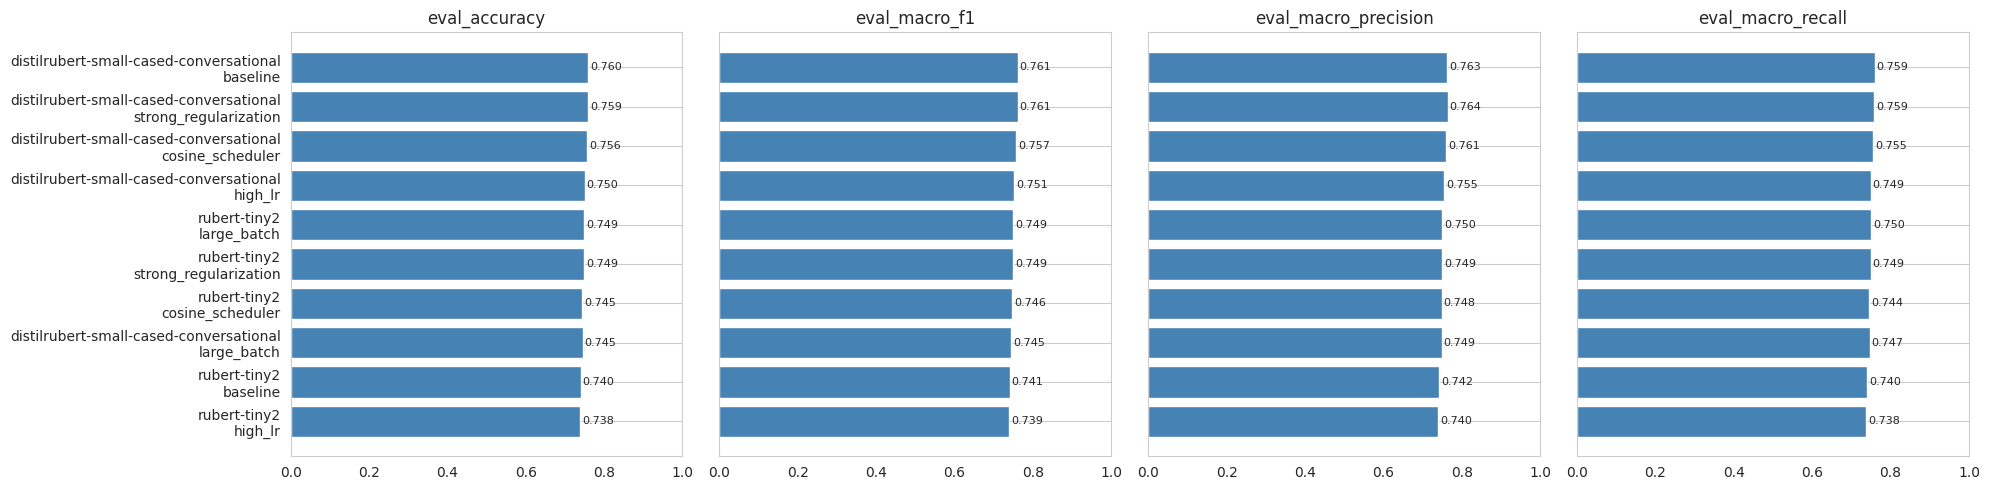

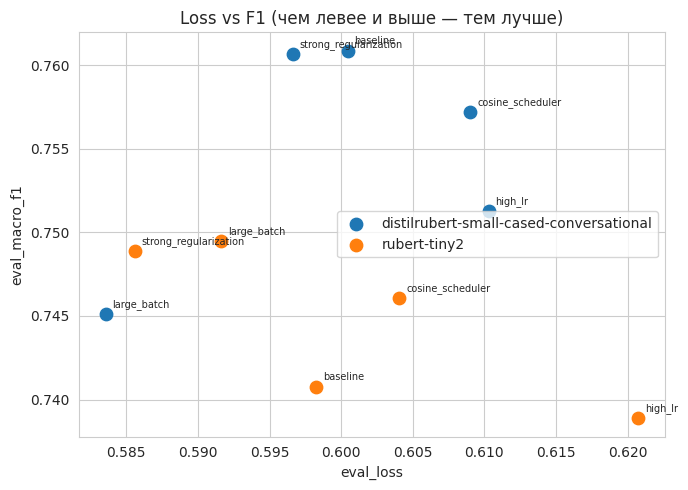

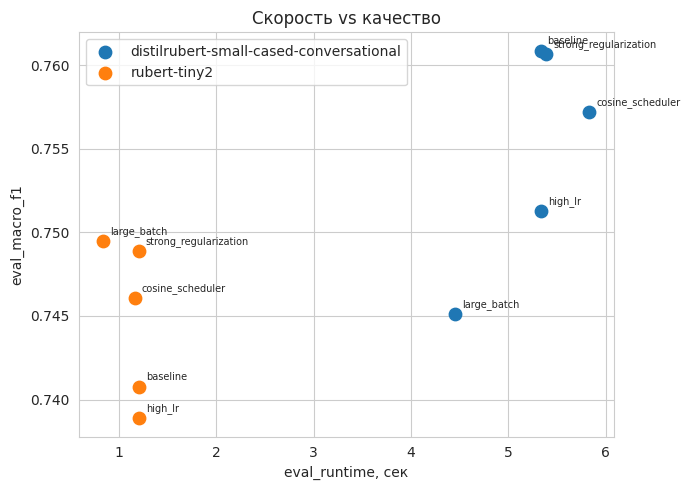

In [19]:
# === Ячейка 18. Бар-чарты: сравнение моделей и конфигов по метрикам ===
def plot_comparison_bars(results_df):
    df = results_df.copy()
    df['run'] = df['base_model'].str.split('/').str[-1] + '\n' + df['config_name']

    metrics = [m for m in ['eval_accuracy', 'eval_macro_f1',
                           'eval_macro_precision', 'eval_macro_recall']
               if m in df.columns]

    fig, axes = plt.subplots(1, len(metrics), figsize=(5 * len(metrics), 5), sharey=True)
    if len(metrics) == 1:
        axes = [axes]

    df_sorted = df.sort_values('eval_macro_f1', ascending=True)
    for ax, m in zip(axes, metrics):
        ax.barh(df_sorted['run'], df_sorted[m], color='steelblue')
        ax.set_title(m); ax.set_xlim(0, 1); ax.grid(axis='x')
        for i, v in enumerate(df_sorted[m]):
            ax.text(v + 0.005, i, f'{v:.3f}', va='center', fontsize=8)
    plt.tight_layout(); plt.show()


def plot_loss_vs_f1(results_df):
    plt.figure(figsize=(7, 5))
    for base, sub in results_df.groupby('base_model'):
        plt.scatter(sub['eval_loss'], sub['eval_macro_f1'],
                    s=80, label=base.split('/')[-1])
        for _, r in sub.iterrows():
            plt.annotate(r['config_name'],
                         (r['eval_loss'], r['eval_macro_f1']),
                         fontsize=7, xytext=(5, 5), textcoords='offset points')
    plt.xlabel('eval_loss'); plt.ylabel('eval_macro_f1')
    plt.title('Loss vs F1 (чем левее и выше — тем лучше)')
    plt.legend(); plt.grid(True); plt.tight_layout(); plt.show()


def plot_runtime_vs_quality(results_df):
    if 'eval_runtime' not in results_df.columns:
        return
    plt.figure(figsize=(7, 5))
    for base, sub in results_df.groupby('base_model'):
        plt.scatter(sub['eval_runtime'], sub['eval_macro_f1'],
                    s=80, label=base.split('/')[-1])
        for _, r in sub.iterrows():
            plt.annotate(r['config_name'],
                         (r['eval_runtime'], r['eval_macro_f1']),
                         fontsize=7, xytext=(5, 5), textcoords='offset points')
    plt.xlabel('eval_runtime, сек'); plt.ylabel('eval_macro_f1')
    plt.title('Скорость vs качество')
    plt.legend(); plt.grid(True); plt.tight_layout(); plt.show()


plot_comparison_bars(results_df)
plot_loss_vs_f1(results_df)
plot_runtime_vs_quality(results_df)

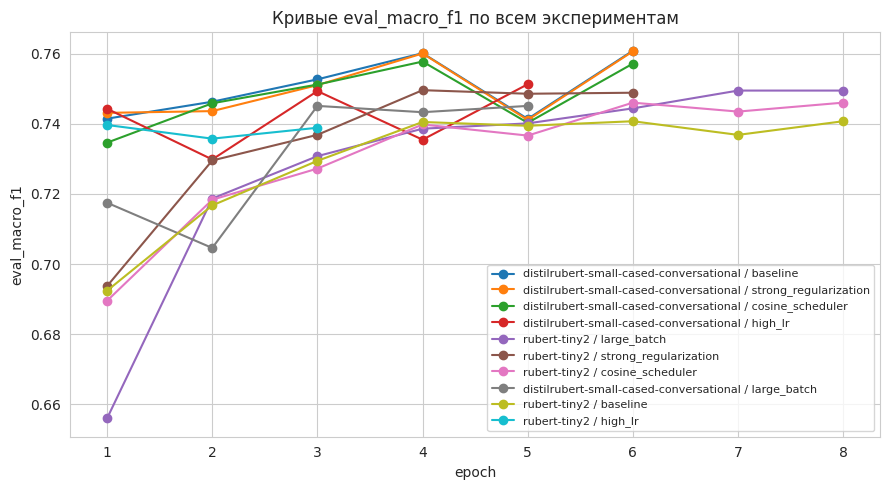

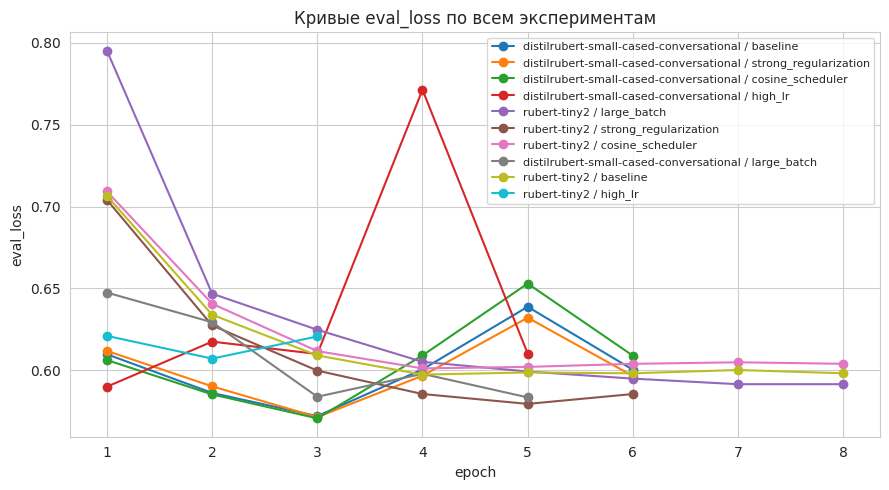

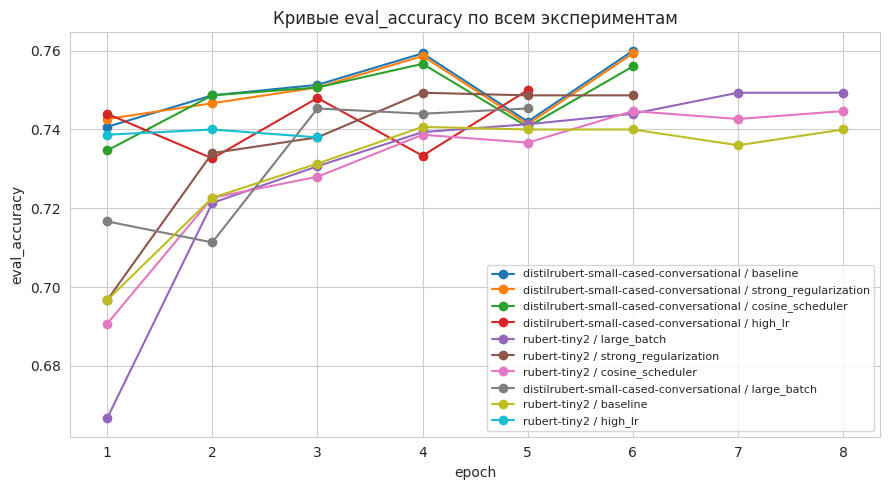

In [20]:
# === Ячейка 19. Кривые обучения для всех экспериментов на одном поле ===
def plot_all_eval_curves(results_df, metric='eval_macro_f1'):
    plt.figure(figsize=(9, 5))
    for _, r in results_df.iterrows():
        try:
            hist = load_history(r['output_dir'])
            _, eval_hist = split_train_eval(hist)
            if metric in eval_hist.columns and eval_hist[metric].notna().any():
                label = f"{r['base_model'].split('/')[-1]} / {r['config_name']}"
                plt.plot(eval_hist['epoch'], eval_hist[metric],
                         marker='o', label=label)
        except FileNotFoundError:
            continue
    plt.title(f'Кривые {metric} по всем экспериментам')
    plt.xlabel('epoch'); plt.ylabel(metric)
    plt.legend(fontsize=8, loc='best'); plt.grid(True); plt.tight_layout(); plt.show()


plot_all_eval_curves(results_df, 'eval_macro_f1')
plot_all_eval_curves(results_df, 'eval_loss')
plot_all_eval_curves(results_df, 'eval_accuracy')

Лучшая модель: DeepPavlov/distilrubert-small-cased-conversational
Конфигурация: baseline
macro_f1 = 0.7609 | accuracy = 0.76
Каталог: ./results/DeepPavlov__distilrubert-small-cased-conversational/baseline
Путь к чекпойнту: ./results/DeepPavlov__distilrubert-small-cased-conversational/baseline/checkpoint-2250


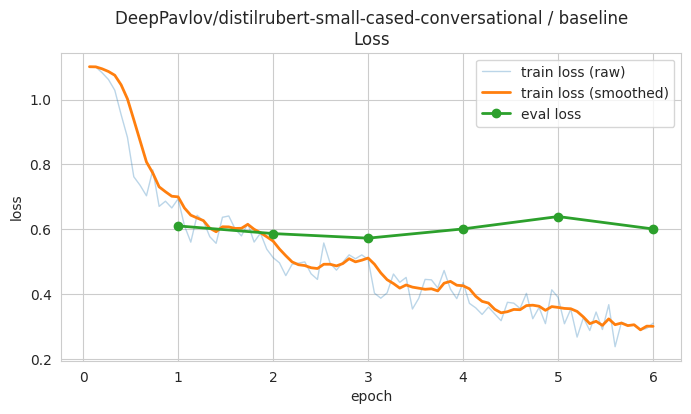

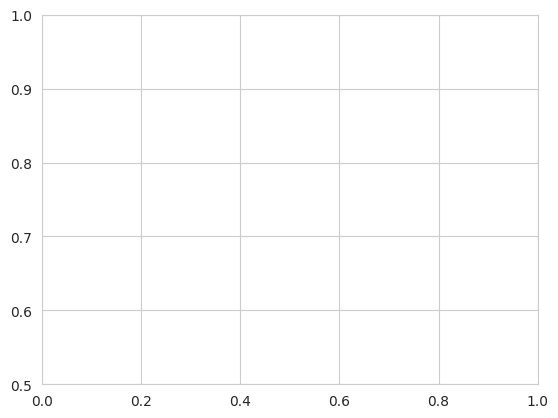

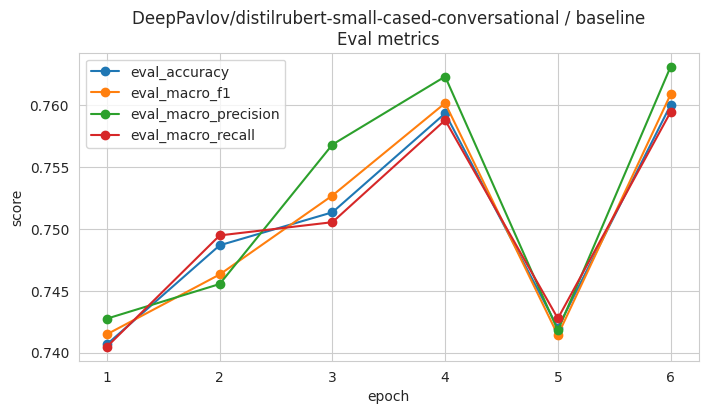

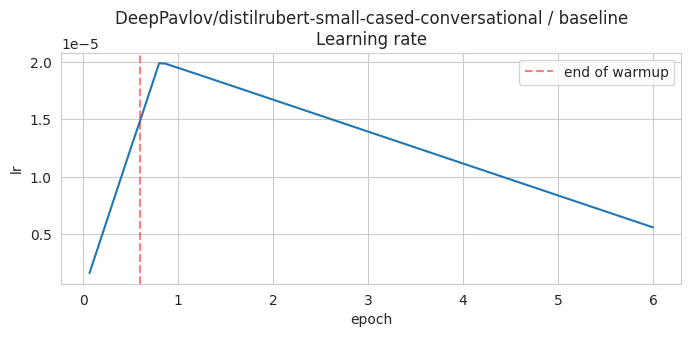

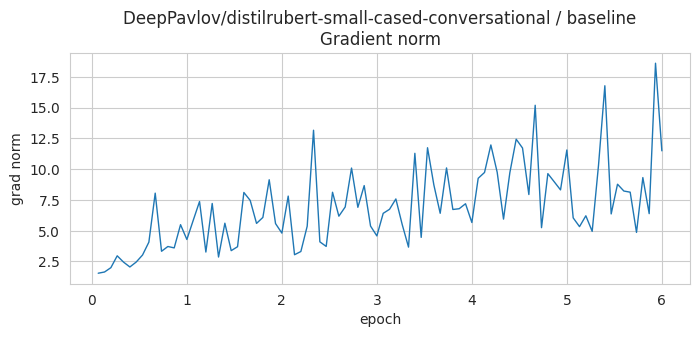

In [21]:
# === Ячейка 20. Поиск пути к лучшей модели ===
def resolve_best_checkpoint(output_dir):
    """Берём последний checkpoint-* или сам output_dir, если чекпойнтов нет."""
    if not os.path.isdir(output_dir):
        return output_dir
    checkpoints = [os.path.join(output_dir, d) for d in os.listdir(output_dir)
                   if d.startswith('checkpoint-')]
    if checkpoints:
        return sorted(checkpoints, key=lambda p: int(p.split('-')[-1]))[-1]
    return output_dir


best_row = results_df.sort_values(
    ['eval_macro_f1', 'eval_accuracy'], ascending=False
).iloc[0]
best_dir = best_row['output_dir']
best_model_path = resolve_best_checkpoint(best_dir)

print('Лучшая модель:', best_row['base_model'])
print('Конфигурация:', best_row['config_name'])
print('macro_f1 =', round(best_row['eval_macro_f1'], 4),
      '| accuracy =', round(best_row['eval_accuracy'], 4))
print('Каталог:', best_dir)
print('Путь к чекпойнту:', best_model_path)

plot_history(best_dir, f"{best_row['base_model']} / {best_row['config_name']}")

In [22]:
# === Ячейка 21. Предсказания лучшей модели на примерах ===
best_pipe = pipeline(
    'sentiment-analysis',
    model=best_model_path,
    tokenizer=best_row['base_model'],
    device=DEVICE,
    truncation=True,
)

for text in examples:
    out = best_pipe(text, truncation=True)
    print(text, '->', out)

Loading weights:   0%|          | 0/40 [00:00<?, ?it/s]

Платье отличное, ткань приятная, села по фигуре, очень довольна покупкой! -> [{'label': 'POSITIVE', 'score': 0.9981415271759033}]
Сумка пришла с оторванной ручкой, ужасное качество, деньги на ветер. -> [{'label': 'NEGATIVE', 'score': 0.9720534086227417}]
Заказ доставили вовремя, размер совпал с таблицей, в целом нормально. -> [{'label': 'POSITIVE', 'score': 0.9397324323654175}]
Туфли красивые, но натирают пятку после получаса носки. -> [{'label': 'NEUTRAL', 'score': 0.8607972860336304}]
Шарф мягкий и тёплый, цвет как на фото, рекомендую продавца. -> [{'label': 'POSITIVE', 'score': 0.9969627261161804}]


In [23]:
# === Ячейка 22. Полная оценка лучшей модели на валидации ===
def predict_with_pipeline(clf, texts, batch_size=32):
    preds = clf(texts, batch_size=batch_size, max_length=256, truncation=True)
    return np.array([normalize_pred_label(p['label']) for p in preds])


val_texts = ['' if x is None else str(x) for x in dataset['validation']['text']]
val_true = np.array([int(y) for y in dataset['validation']['label']])
val_pred = predict_with_pipeline(best_pipe, val_texts)

label_names = [ID2LABEL[i] for i in sorted(ID2LABEL)]

print(classification_report(
    val_true, val_pred, target_names=label_names, digits=4, zero_division=0
))

              precision    recall  f1-score   support

     NEUTRAL     0.6454    0.6732    0.6590       511
    POSITIVE     0.8737    0.8583    0.8659       508
    NEGATIVE     0.7415    0.7214    0.7313       481

    accuracy                         0.7513      1500
   macro avg     0.7535    0.7510    0.7521      1500
weighted avg     0.7535    0.7513    0.7523      1500



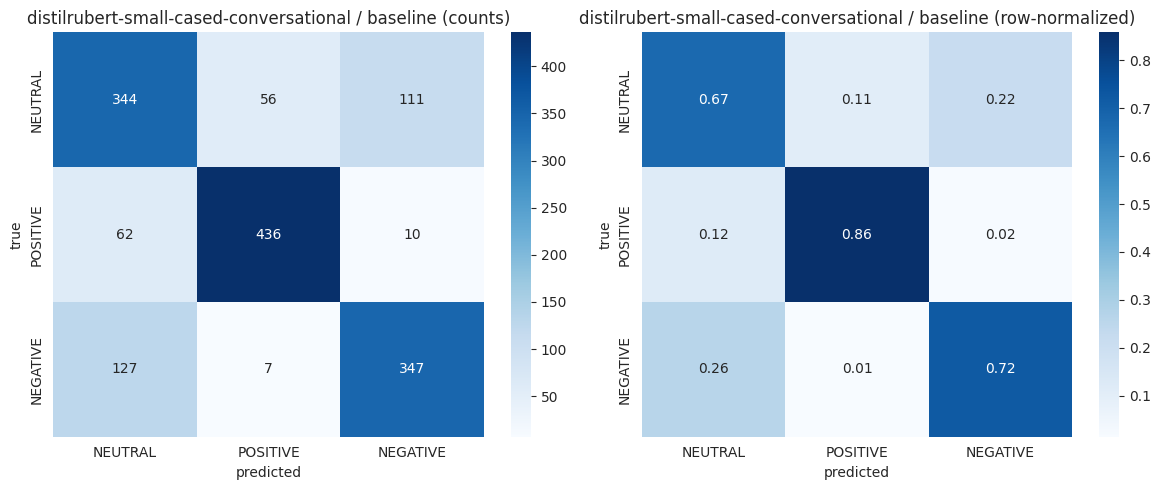

In [24]:
# === Ячейка 23. Матрица ошибок: абсолютная и нормированная ===
def plot_confusion(y_true, y_pred, label_names, title='Confusion matrix'):
    cm = confusion_matrix(y_true, y_pred)
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=label_names, yticklabels=label_names, ax=axes[0])
    axes[0].set_title(f'{title} (counts)')
    axes[0].set_xlabel('predicted'); axes[0].set_ylabel('true')

    sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues',
                xticklabels=label_names, yticklabels=label_names, ax=axes[1])
    axes[1].set_title(f'{title} (row-normalized)')
    axes[1].set_xlabel('predicted'); axes[1].set_ylabel('true')

    plt.tight_layout(); plt.show()


plot_confusion(val_true, val_pred, label_names,
               title=f"{best_row['base_model'].split('/')[-1]} / {best_row['config_name']}")

,class,precision,recall,f1,support
0,NEUTRAL,0.645403,0.673190,0.659004,511
1,POSITIVE,0.873747,0.858268,0.865938,508
2,NEGATIVE,0.741453,0.721414,0.731296,481


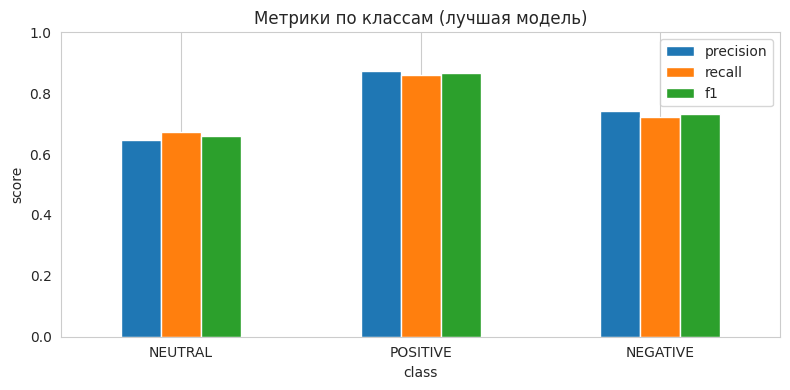

In [25]:
# === Ячейка 24. Per-class метрики лучшей модели ===
def plot_per_class_metrics(y_true, y_pred, label_names):
    pr, rc, f1, sup = precision_recall_fscore_support(
        y_true, y_pred, average=None, zero_division=0,
        labels=list(range(len(label_names)))
    )
    plot_df = pd.DataFrame({
        'class': label_names,
        'precision': pr, 'recall': rc, 'f1': f1, 'support': sup,
    })
    display(plot_df)

    plot_df.set_index('class')[['precision', 'recall', 'f1']].plot(
        kind='bar', figsize=(8, 4), ylim=(0, 1), rot=0
    )
    plt.title('Метрики по классам (лучшая модель)')
    plt.ylabel('score'); plt.grid(axis='y'); plt.tight_layout(); plt.show()


plot_per_class_metrics(val_true, val_pred, label_names)

In [26]:
# === Ячейка 25. Анализ ошибок: примеры неправильных предсказаний ===
errors_df = pd.DataFrame({
    'text': val_texts,
    'true': [ID2LABEL[y] for y in val_true],
    'pred': [ID2LABEL[y] for y in val_pred],
})
errors_df = errors_df[errors_df['true'] != errors_df['pred']].reset_index(drop=True)

print(f'Всего ошибок: {len(errors_df)} из {len(val_texts)} '
      f'({len(errors_df) / len(val_texts):.1%})')

# Распределение типов ошибок
err_pivot = errors_df.groupby(['true', 'pred']).size().unstack(fill_value=0)
print('\nМатрица ошибок (true -> pred):')
print(err_pivot)

# По 3 примера на каждый тип ошибки
for (t, p), grp in errors_df.groupby(['true', 'pred']):
    print(f'\n--- true={t}, pred={p} (всего {len(grp)}) ---')
    for txt in grp['text'].head(3).tolist():
        print('•', txt[:200])

Всего ошибок: 373 из 1500 (24.9%)

Матрица ошибок (true -> pred):
pred      NEGATIVE  NEUTRAL  POSITIVE
true                                 
NEGATIVE         0      127         7
NEUTRAL        111        0        56
POSITIVE        10       62         0

--- true=NEGATIVE, pred=NEUTRAL (всего 127) ---
• Заказ пришол довольно быстро, но из одежды лезут нитки. Если чесно не советую.
• Заказывала эту куртку ранее в размере S и было шикарное качество, почти Z*ra один в один, единственно крой был немного несуразен в бедрах, уж очень узко и не застегивалось. Продала эту куртку знакомой
• Качество и фасон совсем никудышные, на картинку не похоже

--- true=NEGATIVE, pred=POSITIVE (всего 7) ---
• Заказ шел месяц, упакована хорошо. Неприятный запах есть. Куртка на теплую зиму, открытая шея, капюшон как будто пришит только для красоты, сзади ало что прикрывает, карманы пришиты на разных уровнях(
• 2 3везды за очень странную доставку. 11.11 оплачено,03.01.18 отправлено из Китая. доставка по Росс

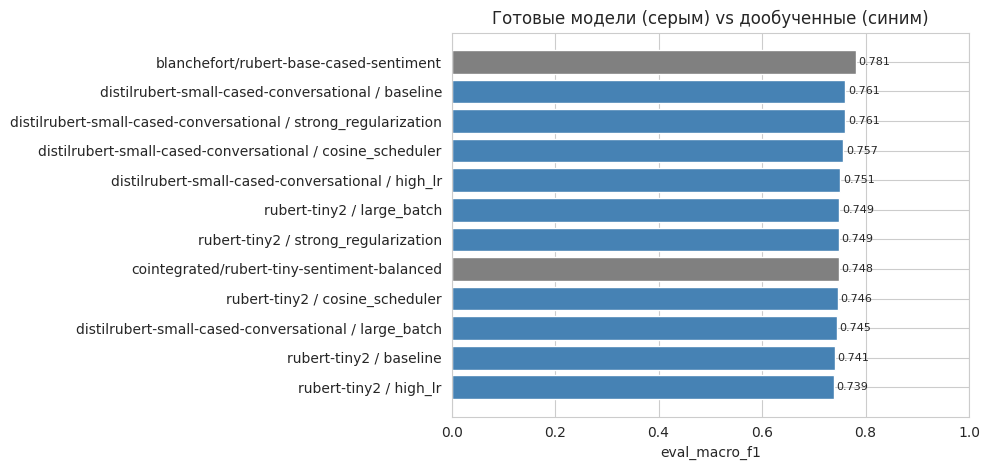

,run,eval_accuracy,eval_macro_precision,eval_macro_recall,eval_macro_f1,kind
0,blanchefort/rubert-base-cased-sentiment,0.782000,0.806526,0.787916,0.780921,pretrained
1,distilrubert-small-cased-conversational / base...,0.760000,0.763099,0.759437,0.760863,finetuned
2,distilrubert-small-cased-conversational / stro...,0.759333,0.763749,0.758806,0.760686,finetuned
3,distilrubert-small-cased-conversational / cosi...,0.756000,0.760815,0.755231,0.757183,finetuned
4,distilrubert-small-cased-conversational / high_lr,0.750000,0.755364,0.749238,0.751292,finetuned
5,rubert-tiny2 / large_batch,0.749333,0.749604,0.749746,0.749492,finetuned
6,rubert-tiny2 / strong_regularization,0.748667,0.749026,0.749131,0.748877,finetuned
7,cointegrated/rubert-tiny-sentiment-balanced,0.744000,0.750438,0.747417,0.748467,pretrained
8,rubert-tiny2 / cosine_scheduler,0.744667,0.748487,0.744343,0.746047,finetuned
9,distilrubert-small-cased-conversational / larg...,0.745333,0.748680,0.746671,0.745116,finetuned


In [27]:
# === Ячейка 26. Сравнение pipeline-моделей и дообученных моделей ===
if len(pipeline_results_df) > 0 and len(results_df) > 0:
    pre = pipeline_results_df.rename(columns={
        'model': 'run',
        'accuracy': 'eval_accuracy',
        'macro_f1': 'eval_macro_f1',
        'macro_precision': 'eval_macro_precision',
        'macro_recall': 'eval_macro_recall',
    }).assign(kind='pretrained')

    ft = results_df.assign(
        run=results_df['base_model'].str.split('/').str[-1] + ' / ' + results_df['config_name'],
        kind='finetuned',
    )[['run', 'eval_accuracy', 'eval_macro_f1',
       'eval_macro_precision', 'eval_macro_recall', 'kind']]

    combined = pd.concat([pre, ft], ignore_index=True).sort_values(
        'eval_macro_f1', ascending=True
    )

    fig, ax = plt.subplots(figsize=(10, max(4, len(combined) * 0.4)))
    colors = combined['kind'].map({'pretrained': 'gray', 'finetuned': 'steelblue'})
    ax.barh(combined['run'], combined['eval_macro_f1'], color=colors)
    ax.set_xlim(0, 1); ax.set_xlabel('eval_macro_f1')
    ax.set_title('Готовые модели (серым) vs дообученные (синим)')
    for i, v in enumerate(combined['eval_macro_f1']):
        ax.text(v + 0.005, i, f'{v:.3f}', va='center', fontsize=8)
    plt.tight_layout(); plt.show()

    display(combined.sort_values('eval_macro_f1', ascending=False).reset_index(drop=True))